# Crater Candidate Detection — Module: Geophysical Pipeline (Prototype)

**Goal.** Build and validate a pipeline that flags *candidate* impact-crater sites
from geophysical fields (gravity, topography, magnetic), to be triaged afterward in QGIS.

**Important framing.** This notebook does **not** discover craters. It generates
*ranked hypotheses worth field-checking*. Confirmation requires shock metamorphism,
shatter cones, or drill cores — none of which live in a gravity grid.

## Strategy of this prototype
The detection logic is the hard, bug-prone part; data loading is trivial by comparison.
So we **develop and validate the entire pipeline on synthetic data with a planted crater
of known location**, prove the method recovers it, then swap a single cell for the real
`pyshtools` model fetch when running on actual Australia data.

**One global model, regionally-windowed.** EGM2008 / XGM2019E (gravity), Earth2014
(topography) and EMAG2 (magnetic) are single *global* spherical-harmonic models. We
synthesize them only over a local lat/lon window per region of interest — same model,
cheaper evaluation. Australia is the development region: best open terrestrial data,
several well-characterized known craters (Wolfe Creek, Gosses Bluff, Spider, Boxhole)
for calibration, and quiet cratonic geology while debugging.


jupyter nbconvert --to pdf ImpactCratering23.ipynb

## 1. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter, minimum_filter

np.set_printoptions(suppress=True)

## 2. Input field — SYNTHETIC (swap this cell for the real fetch later)

> **This is the ONLY cell you replace for real data.** Everything downstream operates on
> `x, y, field` and does not care where they came from.

The synthetic field mimics what a real *residual-ready* gravity map looks like:
a smooth long-wavelength **regional background**, plus **planted craters** (a central
negative anomaly from low-density breccia fill, with a faint positive rim), plus
**correlated geological noise** and white measurement noise of comparable amplitude —
so a naive "find the deepest point" approach would fail.

### Real-data replacement (run locally, not in a locked-down sandbox)
```python
import pyshtools as pysh
# Gravity model, global, synthesized then windowed to Australia
clm = pysh.datasets.Earth.EGM2008(lmax=720)          # or XGM2019E
grid = clm.expand(lmax=720)                           # global grid
# ... slice to an Australian lat/lon window, convert to mGal anomaly ...
# x, y = window axes (km or deg);  field = 2D anomaly array
```
The downstream cells then run unchanged.

In [2]:
def make_synthetic_field(nx=200, ny=200, seed=42, planted=None):
    """Synthetic gravity-anomaly grid (mGal) on a ~200x200 km local window.
    Returns x, y (1D km axes), field (2D mGal), planted (list of true craters)."""
    rng = np.random.default_rng(seed)
    x = np.linspace(0, 200, nx)
    y = np.linspace(0, 200, ny)
    X, Y = np.meshgrid(x, y)

    # Smooth regional background (long-wavelength == low-degree SH)
    bg = (8*np.sin(2*np.pi*X/350 + 0.4)
          + 6*np.cos(2*np.pi*Y/300 - 0.7)
          + 4*np.sin(2*np.pi*(X+Y)/500))

    # Planted craters: (cx, cy, radius_km, central_depth_mGal)
    if planted is None:
        planted = [(60, 140, 12, -18),   # large, clear
                   (150, 70,  7, -11),   # medium
                   (110, 160, 4, -6)]    # small, harder
    signal = np.zeros_like(X)
    for cx, cy, r, depth in planted:
        rr = np.sqrt((X-cx)**2 + (Y-cy)**2)
        bowl = depth * np.exp(-(rr**2)/(2*(r*0.6)**2))           # central low
        rim  = abs(depth)*0.25 * np.exp(-((rr-r)**2)/(2*(r*0.18)**2))  # faint rim
        signal += bowl + rim

    white = rng.normal(0, 1.2, X.shape)
    corr  = gaussian_filter(rng.normal(0, 4, X.shape), sigma=6)  # geological noise
    field = bg + signal + corr + white
    return x, y, field, planted

x, y, field, truth = make_synthetic_field()
print("grid:", field.shape, "| field range mGal:",
      round(field.min(),1), "to", round(field.max(),1))
print("planted (cx,cy,r,depth):", truth)

grid: (200, 200) | field range mGal: -19.1 to 21.9
planted (cx,cy,r,depth): [(60, 140, 12, -18), (150, 70, 7, -11), (110, 160, 4, -6)]


## 3. Residual extraction — remove the regional trend

A crater's gravity signature is **short-wavelength**. The regional background is
**long-wavelength**. We fit and subtract a low-order 2D polynomial; what remains is
the residual where local anomalies live.

**Real-data analog:** synthesize the global SH model only up to a low cutoff degree
`L_low` and subtract it from the full-resolution field. Low-degree SH *is* the regional
trend. The polynomial `order` here plays the role of `L_low`:
- too low → regional structure leaks into the residual (false positives)
- too high → you subtract the craters themselves (false negatives)

This is the key parameter to **tune against the known Australian craters.**

In [3]:
def remove_regional_trend(x, y, field, order=3):
    """Fit & subtract a 2D polynomial regional trend. Returns (residual, trend)."""
    X, Y = np.meshgrid(x, y)
    xf, yf, zf = X.ravel(), Y.ravel(), field.ravel()
    cols = [(xf**i)*(yf**j) for i in range(order+1) for j in range(order+1-i)]
    A = np.column_stack(cols)
    coeffs, *_ = np.linalg.lstsq(A, zf, rcond=None)
    trend = (A @ coeffs).reshape(field.shape)
    return field - trend, trend

res, trend = remove_regional_trend(x, y, field, order=3)
print("residual range mGal:", round(res.min(),1), "to", round(res.max(),1),
      "| residual std:", round(res.std(),2))

# Sanity check: each planted crater should now be a clear local minimum
X, Y = np.meshgrid(x, y)
for cx, cy, r, depth in truth:
    ix, iy = np.argmin(abs(x-cx)), np.argmin(abs(y-cy))
    rr = np.sqrt((X-cx)**2 + (Y-cy)**2)
    surround = res[(rr>r*2.5) & (rr<r*3.5)].mean()
    print(f"  crater@({cx},{cy}) r={r}: center={res[iy,ix]:.1f}  "
          f"surround={surround:.1f}  contrast={res[iy,ix]-surround:.1f} mGal")

residual range mGal: -20.6 to 5.4 | residual std: 1.64
  crater@(60,140) r=12: center=-18.1  surround=0.5  contrast=-18.6 mGal
  crater@(150,70) r=7: center=-12.1  surround=-0.0  contrast=-12.1 mGal
  crater@(110,160) r=4: center=-5.1  surround=0.5  contrast=-5.6 mGal


## 4. Detection — score candidates on circular symmetry

A local minimum is **not** enough: sedimentary basins and salt structures are also
negative. What distinguishes an impact crater is **radial symmetry** — the anomaly
depends on distance-from-center, not direction.

For each candidate center we measure:
- **depth** — how much lower the center is than the rim (a bowl), and
- **symmetry** — `1 − azimuthal_scatter / radial_signal`; ~1 = perfectly circular.

`score = depth × symmetry` ranks candidates. An elongated fault trough scores low on
symmetry even if it's deep; a circular crater scores high on both.

> **Caveat to carry to real data:** genuine circular *geological* features (volcanic
> centers, plutons, kimberlites) will also score high here. The synthetic noise has no
> competing circular structures, so the real rank-4-and-below list will be messier.
> That is exactly what the **magnetic layer** and the **QGIS structural pass** are for.
>
> This prototype uses a single fixed `r_test`. Production needs a **multi-scale scan**:
> loop `r_test` over a range and keep the best-scoring radius per location.

In [4]:
def radial_symmetry_score(res, x, y, cx, cy, r_test):
    """Return (depth, symmetry) for a candidate center at test radius r_test."""
    X, Y = np.meshgrid(x, y)
    rr = np.sqrt((X-cx)**2 + (Y-cy)**2)
    bins = np.linspace(0, r_test, 7)
    means, stds = [], []
    for b0, b1 in zip(bins[:-1], bins[1:]):
        m = (rr>=b0) & (rr<b1)
        if m.sum() < 4:
            return 0.0, 0.0
        means.append(res[m].mean()); stds.append(res[m].std())
    means, stds = np.array(means), np.array(stds)
    depth = means[-1] - means[0]                       # >0 if center lower than rim
    radial_signal = means.max() - means.min()
    symmetry = max(0.0, 1 - stds.mean()/(radial_signal + 1e-6))
    return depth, symmetry

def find_candidates(res, x, y, r_test=10, footprint=15, n_top=10):
    """Scan local minima, score each, return ranked list of candidates."""
    mins = (res == minimum_filter(res, size=footprint))
    iy, ix = np.where(mins)
    cands = []
    for j, i in zip(iy, ix):
        cx, cy = x[i], y[j]
        if cx<r_test or cx>x[-1]-r_test or cy<r_test or cy>y[-1]-r_test:
            continue
        depth, sym = radial_symmetry_score(res, x, y, cx, cy, r_test)
        if depth <= 0:
            continue
        cands.append((depth*sym, cx, cy, depth, sym))
    cands.sort(reverse=True)
    return cands[:n_top]

cands = find_candidates(res, x, y, r_test=10, n_top=8)
print("RANK  score   center(km)        depth  symmetry")
for k,(s,cx,cy,d,sym) in enumerate(cands,1):
    print(f"  {k}   {s:6.1f}   ({cx:5.1f},{cy:5.1f})    {d:5.1f}    {sym:.2f}")
print("\nPlanted truth:", [(c[0],c[1]) for c in truth])

RANK  score   center(km)        depth  symmetry
  1     10.1   ( 59.3,138.7)     12.2    0.83
  2      7.2   (151.8, 70.4)      9.4    0.77
  3      3.4   (108.5,159.8)      5.0    0.68
  4      0.5   ( 92.5, 19.1)      1.4    0.33
  5      0.3   ( 60.3,175.9)      1.2    0.22
  6      0.2   (120.6, 37.2)      1.5    0.17
  7      0.2   (109.5, 39.2)      1.3    0.15
  8      0.2   (123.6, 79.4)      0.9    0.20

Planted truth: [(60, 140), (150, 70), (110, 160)]


## 5. Visualize — field, residual, and ranked detections

Left: raw field (regional trend dominates, craters hidden). Middle: residual after
trend removal (craters emerge). Right: residual with top candidates marked — green
circles are the top 3 detections, white crosses are the planted truth. They coincide.

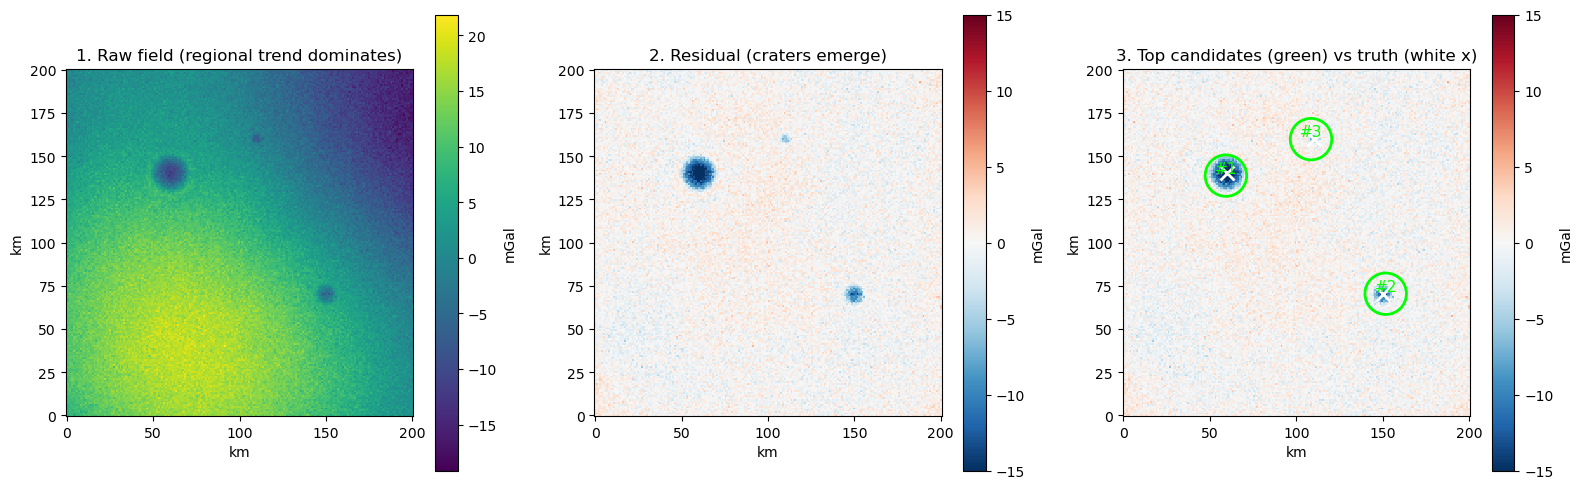

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

im0 = axes[0].pcolormesh(x, y, field, shading="auto", cmap="viridis")
axes[0].set_title("1. Raw field (regional trend dominates)")
fig.colorbar(im0, ax=axes[0], label="mGal")

im1 = axes[1].pcolormesh(x, y, res, shading="auto", cmap="RdBu_r",
                         vmin=-15, vmax=15)
axes[1].set_title("2. Residual (craters emerge)")
fig.colorbar(im1, ax=axes[1], label="mGal")

im2 = axes[2].pcolormesh(x, y, res, shading="auto", cmap="RdBu_r",
                         vmin=-15, vmax=15)
for k,(s,cx,cy,d,sym) in enumerate(cands[:3],1):
    axes[2].add_patch(plt.Circle((cx,cy), 12, fill=False,
                                 color="lime", lw=2))
    axes[2].annotate(f"#{k}", (cx,cy), color="lime",
                     fontsize=11, ha="center", va="bottom")
for cx, cy, r, depth in truth:
    axes[2].plot(cx, cy, "wx", ms=10, mew=2)
axes[2].set_title("3. Top candidates (green) vs truth (white x)")
fig.colorbar(im2, ax=axes[2], label="mGal")

for ax in axes:
    ax.set_xlabel("km"); ax.set_ylabel("km"); ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## 6. Next steps — from prototype to real Australia

1. **Swap cell 2** for the `pyshtools` EGM2008/XGM2019E fetch, windowed to an Australian
   lat/lon box. Run cells 3–5 unchanged.
2. **Calibrate** `order` (≈ `L_low`) and the score threshold against the known craters
   (Wolfe Creek, Gosses Bluff, Spider, Boxhole) — they must land in your top ranks.
3. **Multi-scale**: loop `r_test` over a range of radii; keep best score per location.
4. **Add the magnetic layer** (EMAG2): impact structures often show a ring / central
   magnetic anomaly. Use it to down-weight false positives (volcanic/pluton/kimberlite).
5. **Then, and only then,** introduce ML to *rank* candidates from engineered features
   (circularity index, radial gravity gradient, magnetic ring score). With only ~190
   confirmed structures worldwide — biased toward large, obvious ones — a black-box
   classifier overfits fast. Threshold + symmetry scoring first; ML as a ranker on top.
   Consider pretraining shape recognition on Moon/Mars craters (clean, no erosion) and
   transferring. **Draw negative training samples from all six target regions, not just
   Australia,** or the model learns "looks like Australian basement," not "not a crater."
6. **QGIS pass** on survivors: radial faults, stress lineaments, central uplift. Anything
   that survives *that* is a field/drilling follow-up candidate — not a discovery.